<a href="https://colab.research.google.com/github/Faqih-Huddin-SM/pm-turi4-clustering/blob/main/PM_P9_Faqih_Huddin_SM__2488010061.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Praktikum Pertemuan 9 — Clustering dengan K-Means**

**Identitas Mahasiswa**
Nama : Faqih Huddin SM.
NIM  : 2488010061
Kelas  : Informatika / 5B

Tujuan
1. Menyiapkan data tanpa label untuk clustering (termasuk scaling).
2. Menentukan jumlah cluster optimal dengan metode Elbow.
3. Menerapkan K-Means dan memvisualisasikan hasilnya.
4. Mengevaluasi clustering dengan silhouette score.
5. Menafsirkan makna tiap cluster (segmentasi pelanggan).

Langkah 1 — Menyiapkan data & scaling (wajib).

In [ ]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

rng = np.random.default_rng(42)
def kelompok(n, usia, pendapatan, skor):
    return pd.DataFrame({
        'usia': rng.normal(*usia, n).round().clip(18, 70),
        'pendapatan': (rng.normal(*pendapatan, n) / 1e5).round() * 1e5,
        'skor_belanja': rng.normal(*skor, n).round().clip(1, 100)})
df = pd.concat([
    kelompok(70, (25, 3.5), (6e6, 1.0e6), (80, 7)),
    kelompok(70, (45, 5.0), (15e6, 1.5e6), (50, 8)),
    kelompok(60, (60, 4.0), (4.5e6, 0.8e6), (20, 6))],
    ignore_index=True).sample(frac=1, random_state=1).reset_index(drop=True)
X_scaled = StandardScaler().fit_transform(df)

Langkah 2 — Metode Elbow menentukan K.

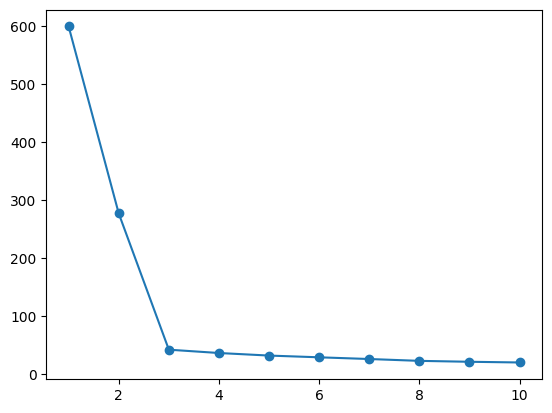

In [ ]:
from sklearn.cluster import KMeans
inertias = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled); inertias.append(km.inertia_)
plt.plot(range(1,11), inertias, marker='o'); plt.show()

Langkah 3 — Menjalankan K-Means (K=3).

In [ ]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)
print(df['cluster'].value_counts())

cluster
1    70
2    70
0    60
Name: count, dtype: int64


Langkah 4 — Evaluasi silhouette score.

In [ ]:
from sklearn.metrics import silhouette_score
print(silhouette_score(X_scaled, df['cluster']))

0.7737135681303848


Langkah 5 — Interpretasi: profil rata-rata tiap cluster.

In [ ]:
profil = df.groupby('cluster')[['usia','pendapatan',
    'skor_belanja']].mean().round(1)
print(profil)   # beri nama tiap cluster berdasarkan profil

# --- penamaan cluster (ditambahkan) ---
nama = {
    profil['skor_belanja'].idxmax(): 'Muda Belanja Tinggi',
    profil['pendapatan'].idxmax():  'Mapan Belanja Sedang',
    profil['skor_belanja'].idxmin(): 'Senior Hemat',
}
profil['nama_cluster'] = profil.index.map(nama)
df['nama_cluster'] = df['cluster'].map(nama)
print(profil)

         usia  pendapatan  skor_belanja
cluster                                
0        59.9   4473333.3          19.0
1        25.2   5880000.0          79.6
2        45.1  15054285.7          50.2
         usia  pendapatan  skor_belanja          nama_cluster
cluster                                                      
0        59.9   4473333.3          19.0          Senior Hemat
1        25.2   5880000.0          79.6   Muda Belanja Tinggi
2        45.1  15054285.7          50.2  Mapan Belanja Sedang


**D. Latihan Mandiri**

6. Jalankan K-Means K=5; bandingkan silhouette score dengan K=3.

In [ ]:
sil_k3 = silhouette_score(X_scaled, df['cluster'])

km5 = KMeans(n_clusters=5, random_state=42, n_init=10)
label_k5 = km5.fit_predict(X_scaled)
sil_k5 = silhouette_score(X_scaled, label_k5)

print(f'Silhouette K=3: {sil_k3:.3f}')
print(f'Silhouette K=5: {sil_k5:.3f}')

Silhouette K=3: 0.774
Silhouette K=5: 0.613


7. Jalankan K-Means tanpa scaling (K=3); bandingkan silhouette-nya. Apa kesimpulannya?

In [ ]:
fitur = ['usia', 'pendapatan', 'skor_belanja']

km_raw = KMeans(n_clusters=3, random_state=42, n_init=10)
label_raw = km_raw.fit_predict(df[fitur])        # TANPA scaling

sil_raw_mentah = silhouette_score(df[fitur], label_raw)   # dinilai di ruang mentah
sil_raw_scaled = silhouette_score(X_scaled, label_raw)    # dinilai di ruang ter-scaling

print(f'Dengan scaling (ruang scaled)  : {sil_k3:.3f}')
print(f'Tanpa scaling  (ruang mentah)  : {sil_raw_mentah:.3f}')
print(f'Tanpa scaling  (ruang scaled)  : {sil_raw_scaled:.3f}')

print(pd.crosstab(df['cluster'], label_raw, rownames=['dengan scaling'], colnames=['tanpa scaling']))

Dengan scaling (ruang scaled)  : 0.774
Tanpa scaling  (ruang mentah)  : 0.740
Tanpa scaling  (ruang scaled)  : 0.203
tanpa scaling    0   1   2
dengan scaling            
0               60   0   0
1               70   0   0
2                0  31  39


8. Buat scatter plot cluster pada fitur usia (x) vs skor_belanja (y).

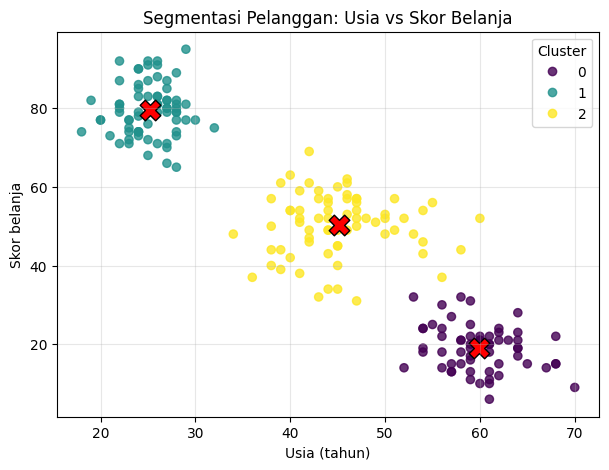

In [ ]:
# centroid dikembalikan ke satuan asli agar bisa digambar
centroid_asli = StandardScaler().fit(df[fitur]).inverse_transform(kmeans.cluster_centers_)

plt.figure(figsize=(7, 5))
sc = plt.scatter(df['usia'], df['skor_belanja'], c=df['cluster'], cmap='viridis', s=35, alpha=.8)
plt.scatter(centroid_asli[:, 0], centroid_asli[:, 2], c='red', marker='X', s=220,
            edgecolor='black', label='Centroid')
plt.xlabel('Usia (tahun)'); plt.ylabel('Skor belanja')
plt.title('Segmentasi Pelanggan: Usia vs Skor Belanja')
plt.legend(*sc.legend_elements(), title='Cluster')
plt.grid(alpha=.3); plt.show()

**E. Refleksi**

9. Bagaimana K-Means menemukan kelompok tanpa label?

Jawab: K-Means mengelompokkan data berdasarkan kemiripan jaraknya ketika ada data yang berdekatan akan masuk ke kelompok yang sama lalu nama kelompok baru diberikan setelah melihat karakteristik anggotanya

10. Mengapa metode Elbow menunjukkan siku di K=3 pada data ini?

Jawab: Karena nilai inertia turun drastis sampai K = 3 lalu penurunannya mulai sedikit dimana tiga kelompok sudah cukup mewakili pola data

11. Mengapa scaling penting, dan apa dampaknya bila dilewatkan?

Jawab: Scaling menyamakan skala angka setiap fitur tanpa scaling, pendapatan yang nilainya jutaan akan lebih berpengaruh daripada usia dan skor belanja, sehingga hasil pengelompokan bisa kurang tepat